<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HancockXGB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
Merged data shape: (763, 49)

Target source: hpv_association_p16
Predictors: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
Target distribution:
HPV_Label
0    191
1    141
Name: count, dtype: int64
Fold 1: train=221, validation=111, threshold=0.625, BA=0.6559
Fold 2: train=221, validation=111, threshold=0.705, BA=0.6956
Fold 3: train=222, validation=110, threshold=0.700, BA=0.6969

3-FOLD RESULTS:
 Fold  N_Train  N_Validation  Scale_Pos_Weight  Accuracy  Balanced_Accuracy  Precision   Recall       F1  Threshold  ROC_AUC   PR_AUC
    1      221           111          1.351064  0.684685           0.655918   0.687500 0.468085 0.556962      0.625 0.689328 0.705336
    2      221           111          1.351064  0.720721           0.695645   0.735294 0.531915 0.617284

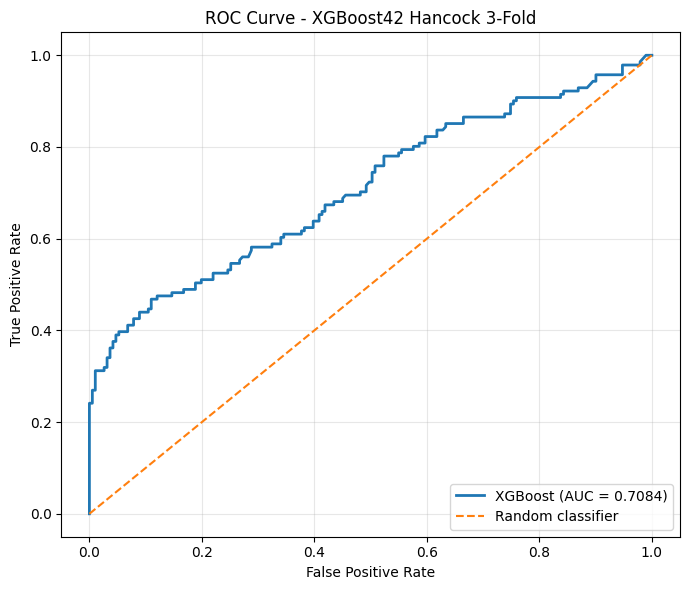

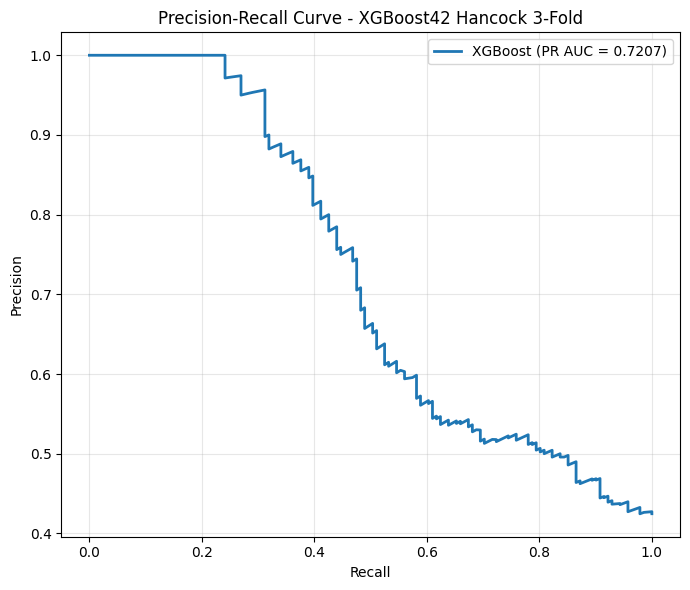

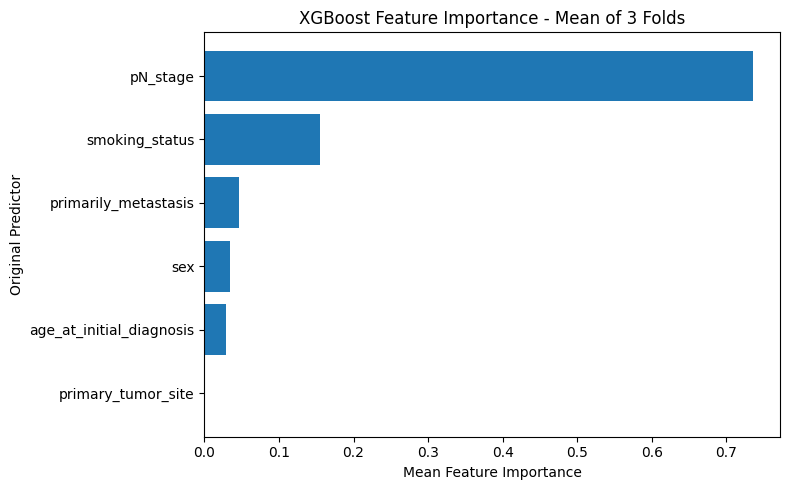

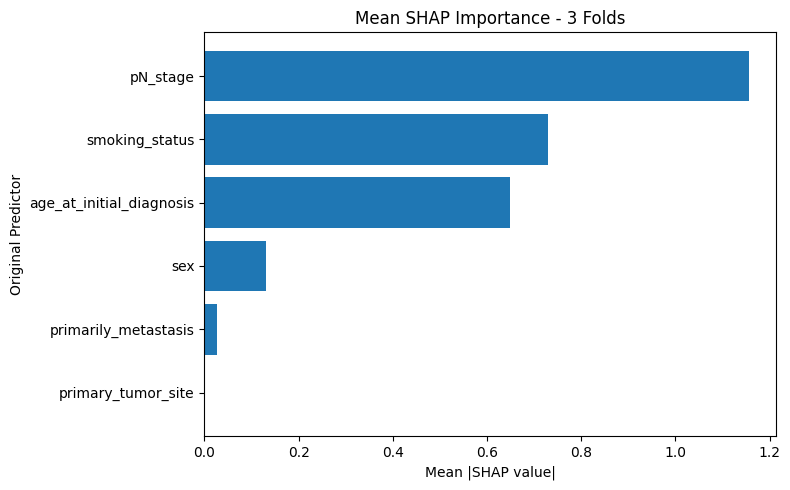

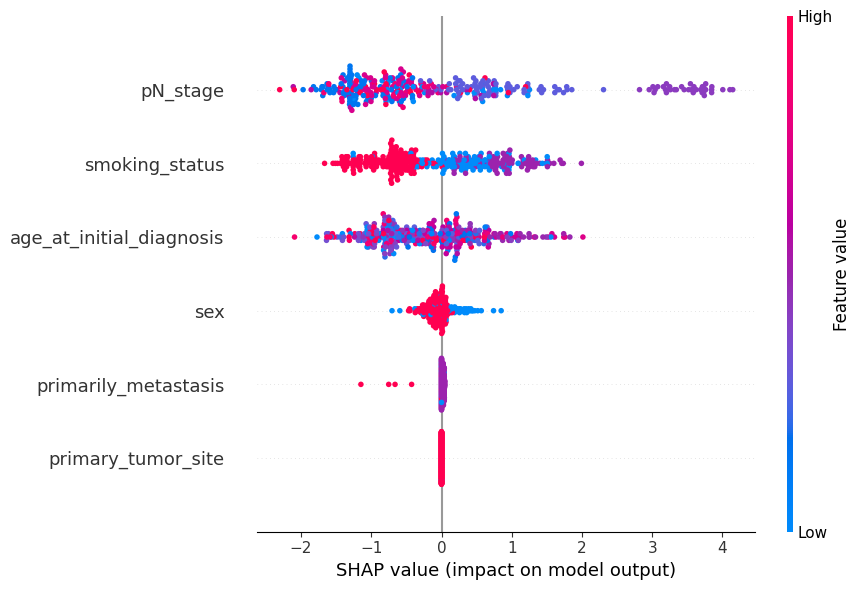

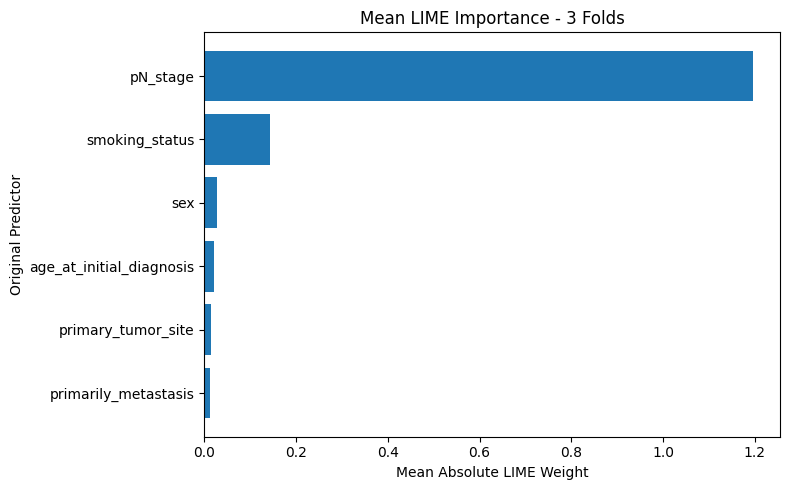


XGBOOST42_HANCOCK 3-FOLD SUMMARY
Model: XGBoost
Original predictors: 6
Estimators: 100
Learning rate: 0.1
Random state: 42
Folds: 3
Split: Stratified 3-fold CV; no test set
SMOTE: No
Class weighting: Training-fold scale_pos_weight
Encoding: OneHotEncoder(handle_unknown='ignore')
Scaling: StandardScaler on age; fitted within each training fold
Threshold: Validation balanced accuracy within each fold

Mean fold metrics:
                       mean       std
Scale_Pos_Weight   1.354610  0.006142
Accuracy           0.713923  0.026502
Balanced_Accuracy  0.682818  0.023305
Precision          0.777295  0.116613
Recall             0.475177  0.053545
F1                 0.584652  0.030463
Threshold          0.676667  0.044814
ROC_AUC            0.702621  0.022037
PR_AUC             0.713675  0.008968

Pooled out-of-fold metrics:
Accuracy             0.713855
Balanced_Accuracy    0.682615
Precision            0.761364
Recall               0.475177
F1                   0.585153
Threshold         

In [ ]:
!pip install -q shap lime
import os,json,random,warnings,joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from google.colab import drive
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,precision_score,
 recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix,
 classification_report,roc_curve,precision_recall_curve)
from xgboost import XGBClassifier
warnings.filterwarnings("ignore",category=FutureWarning)
SEED=42
random.seed(SEED);np.random.seed(SEED)
os.environ["PYTHONHASHSEED"]=str(SEED)
drive.mount("/content/drive")
# LOAD AND PREPARE DATA
BASE="/content/drive/MyDrive"
OUT_DIR=os.path.join(BASE,"XGB_results_3fold")
os.makedirs(OUT_DIR,exist_ok=True)
def load_json_table(path):
 with open(path,"r",encoding="utf-8") as f:obj=json.load(f)
 if isinstance(obj,list):return pd.DataFrame(obj)
 if isinstance(obj,dict):
  for key in ["data","records","patients","items"]:
   if key in obj and isinstance(obj[key],list):return pd.DataFrame(obj[key])
  return pd.DataFrame(obj)
 raise ValueError(f"Cannot read table from {path}")
clinical=load_json_table(os.path.join(BASE,"clinical_data.json"))
pathology=load_json_table(os.path.join(BASE,"pathological_data.json"))
if "patient_id" not in clinical.columns or "patient_id" not in pathology.columns:
 raise KeyError("Both clinical and pathological files must contain patient_id.")
df=clinical.merge(pathology,on="patient_id",how="left",suffixes=("","_path"))
print("Merged data shape:",df.shape)
target_candidates=["hpv_association_p16","hpv_association_p16_path"]
target_col=next((c for c in target_candidates if c in df.columns),None)
if target_col is None:
 raise KeyError(f"HPV target not found. Available columns: {df.columns.tolist()}")
def normalize_label(value):
 if pd.isna(value):return np.nan
 label=str(value).strip().lower()
 if label in {"positive","pos","1","true","yes"}:return 1
 if label in {"negative","neg","0","false","no"}:return 0
 return np.nan
feature_candidates={"age_at_initial_diagnosis":["age_at_initial_diagnosis"],
 "sex":["sex"],"smoking_status":["smoking_status"],
 "primary_tumor_site":["primary_tumor_site"],
 "primarily_metastasis":["primarily_metastasis"],
 "pN_stage":["pN_stage","pN_stage_path","pathological_N_stage",
 "pathologic_N_stage","pathological_n_stage","pN"]}
resolved={}
for feature,candidates in feature_candidates.items():
 match=next((c for c in candidates if c in df.columns),None)
 if match is None:raise KeyError(f"Missing predictor '{feature}'; checked {candidates}")
 resolved[feature]=match
model_df=pd.DataFrame(index=df.index)
model_df["patient_id"]=df["patient_id"]
for feature,source_col in resolved.items():model_df[feature]=df[source_col]
model_df["HPV_Label"]=df[target_col].map(normalize_label)
model_df=model_df.dropna(subset=["HPV_Label"]).copy()
model_df["HPV_Label"]=model_df["HPV_Label"].astype(int)
model_df=model_df.drop_duplicates(subset=["patient_id"],keep="first").copy()
features=list(feature_candidates.keys())
numeric_features=["age_at_initial_diagnosis"]
categorical_features=[c for c in features if c not in numeric_features]
missing_strings={"","nan","none","null","na","n/a"}
for col in categorical_features:
 def clean_category(value):
  if pd.isna(value):return np.nan
  value=str(value).strip()
  return np.nan if value.lower() in missing_strings else value
 model_df[col]=model_df[col].apply(clean_category)
model_df["age_at_initial_diagnosis"]=pd.to_numeric(
 model_df["age_at_initial_diagnosis"],errors="coerce")
print("\nTarget source:",target_col)
print("Predictors:",features)
print("Target distribution:")
print(model_df["HPV_Label"].value_counts().sort_index())
if model_df["HPV_Label"].nunique()!=2:
 raise ValueError("The dataset must contain both HPV classes.")
# STRATIFIED 3-FOLD CROSS-VALIDATION — NO TEST SET
N_SPLITS=3
cv=StratifiedKFold(n_splits=N_SPLITS,shuffle=True,random_state=SEED)
thresholds=np.linspace(0.10,0.90,161)
fold_results=[];oof_true=[];oof_prob=[];oof_pred=[];oof_ids=[]
shap_values_all=[];shap_data_all=[];lime_rows=[];all_importance=[]
models=[]
def make_preprocessor():
 try:onehot=OneHotEncoder(handle_unknown="ignore",sparse_output=False)
 except TypeError:onehot=OneHotEncoder(handle_unknown="ignore",sparse=False)
 return ColumnTransformer(transformers=[
  ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),
   ("scaler",StandardScaler())]),numeric_features),
  ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
   ("onehot",onehot)]),categorical_features)],
  remainder="drop",verbose_feature_names_out=False)
def calculate_metrics(y_true,probabilities,predictions,threshold):
 both_classes=len(np.unique(y_true))==2
 return {"Accuracy":accuracy_score(y_true,predictions),
  "Balanced_Accuracy":balanced_accuracy_score(y_true,predictions),
  "Precision":precision_score(y_true,predictions,zero_division=0),
  "Recall":recall_score(y_true,predictions,zero_division=0),
  "F1":f1_score(y_true,predictions,zero_division=0),
  "Threshold":float(threshold),
  "ROC_AUC":roc_auc_score(y_true,probabilities) if both_classes else np.nan,
  "PR_AUC":average_precision_score(y_true,probabilities)
  if both_classes else np.nan}
def original_feature(name):
 for feature in features:
  if name==feature or name.startswith(feature+"_"):return feature
 return name
for fold,(train_idx,val_idx) in enumerate(cv.split(model_df[features],
 model_df["HPV_Label"]),1):
 train=model_df.iloc[train_idx].copy()
 val=model_df.iloc[val_idx].copy()
 preprocessor=make_preprocessor()
 X_train=preprocessor.fit_transform(train[features])
 X_val=preprocessor.transform(val[features])
 y_train=train["HPV_Label"].to_numpy()
 y_val=val["HPV_Label"].to_numpy()
 try:encoded_names=preprocessor.get_feature_names_out().tolist()
 except (AttributeError,TypeError):
  encoded_names=[f"encoded_feature_{i}" for i in range(X_train.shape[1])]
 counts=np.bincount(y_train,minlength=2)
 if np.any(counts==0):raise ValueError("Both HPV classes must be present in each fold.")
 class_weights={i:float(len(y_train)/(2*counts[i])) for i in range(2)}
 scale_pos_weight=float(counts[0]/counts[1])
 model=XGBClassifier(n_estimators=100,learning_rate=0.1,
  scale_pos_weight=scale_pos_weight,random_state=SEED,eval_metric="logloss")
 model.fit(X_train,y_train)
 val_prob=model.predict_proba(X_val)[:,1]
 threshold_scores=[balanced_accuracy_score(y_val,(val_prob>=t).astype(int))
  for t in thresholds]
 best_score=max(threshold_scores)
 best_threshold=float(min((t for t,s in zip(thresholds,threshold_scores)
  if s==best_score),key=lambda t:abs(t-0.5)))
 val_pred=(val_prob>=best_threshold).astype(int)
 metrics=calculate_metrics(y_val,val_prob,val_pred,best_threshold)
 fold_results.append({"Fold":fold,"N_Train":len(train),"N_Validation":len(val),
  "Scale_Pos_Weight":scale_pos_weight,**metrics})
 oof_true.extend(y_val.tolist());oof_prob.extend(val_prob.tolist())
 oof_pred.extend(val_pred.tolist());oof_ids.extend(val["patient_id"].tolist())
 models.append({"model":model,"preprocessor":preprocessor,
  "threshold":best_threshold,"encoded_feature_names":encoded_names})
 # SHAP values grouped back to the six original predictors
 explainer=shap.TreeExplainer(model)
 sv=explainer.shap_values(X_val)
 if isinstance(sv,list):sv=sv[-1]
 sv=np.asarray(sv)
 if sv.ndim==3:sv=sv[:,:,1]
 grouped=np.column_stack([sv[:,[i for i,n in enumerate(encoded_names)
  if original_feature(n)==feature]].sum(axis=1)
  if any(original_feature(n)==feature for n in encoded_names)
  else np.zeros(len(val)) for feature in features])
 shap_values_all.append(grouped)
 shap_data_all.append(val[features].reset_index(drop=True))
 # LIME local explanations, averaged across validation patients
 lime_explainer=LimeTabularExplainer(np.asarray(X_train),
  feature_names=encoded_names,class_names=["HPV Negative","HPV Positive"],
  mode="classification",discretize_continuous=True,random_state=SEED)
 for row in np.asarray(X_val):
  explanation=lime_explainer.explain_instance(row,model.predict_proba,
   num_features=len(encoded_names))
  row_importance={feature:0.0 for feature in features}
  for term,weight in explanation.as_list(label=1):
   for feature in features:
    if term==feature or term.startswith(feature+"_") or term.startswith(feature+" "):
     row_importance[feature]+=abs(float(weight));break
  lime_rows.append(row_importance)
 importance=dict(zip(encoded_names,model.feature_importances_))
 all_importance.append({feature:sum(value for name,value in importance.items()
  if original_feature(name)==feature) for feature in features})
 print(f"Fold {fold}: train={len(train)}, validation={len(val)}, "
  f"threshold={best_threshold:.3f}, BA={metrics['Balanced_Accuracy']:.4f}")
# FOLD METRICS AND POOLED OUT-OF-FOLD RESULTS
oof_true=np.asarray(oof_true);oof_prob=np.asarray(oof_prob)
oof_pred=np.asarray(oof_pred)
fold_df=pd.DataFrame(fold_results)
summary_df=fold_df.drop(columns=["Fold","N_Train","N_Validation"]).agg(
 ["mean","std"]).T
oof_metrics=calculate_metrics(oof_true,oof_prob,oof_pred,
 float(fold_df["Threshold"].mean()))
print("\n3-FOLD RESULTS:")
print(fold_df.to_string(index=False))
print("\nMEAN ± SD:")
print(summary_df)
print("\nPOOLED OUT-OF-FOLD METRICS:")
print(pd.Series(oof_metrics))
cm=confusion_matrix(oof_true,oof_pred,labels=[0,1])
print("\nOut-of-fold confusion matrix:\n",cm)
print("\nOut-of-fold classification report:\n",
 classification_report(oof_true,oof_pred,labels=[0,1],
 target_names=["HPV Negative","HPV Positive"],zero_division=0))
# SAVE RESULTS
fold_df.to_csv(os.path.join(OUT_DIR,"fold_metrics.csv"),index=False)
summary_df.to_csv(os.path.join(OUT_DIR,"metrics_mean_sd.csv"))
predictions_df=pd.DataFrame({"patient_id":oof_ids,"y_true":oof_true,
 "probability_positive":oof_prob,"prediction":oof_pred})
predictions_df.to_csv(os.path.join(OUT_DIR,"oof_predictions.csv"),index=False)
settings={"model":"XGBClassifier","seed":SEED,"features":features,
 "selected_source_columns":resolved,"target_column":target_col,"folds":N_SPLITS,
 "threshold_selection":"Maximum validation balanced accuracy per fold",
 "smote":False,"validation_design":"Stratified 3-fold CV; no test set",
 "model_parameters":{"n_estimators":100,"learning_rate":0.1,
 "eval_metric":"logloss"}}
with open(os.path.join(OUT_DIR,"settings.json"),"w",encoding="utf-8") as f:
 json.dump(settings,f,indent=2)
joblib.dump(models,os.path.join(OUT_DIR,"XGB42_Hancock_3fold_models.joblib"))
print("\nSaved fold metrics and OOF predictions to:",OUT_DIR)
# ROC / AUC CURVE — POOLED OUT-OF-FOLD PREDICTIONS
fpr,tpr,_=roc_curve(oof_true,oof_prob)
auc_curve=roc_auc_score(oof_true,oof_prob)
plt.figure(figsize=(7,6))
plt.plot(fpr,tpr,linewidth=2,label=f"XGBoost (AUC = {auc_curve:.4f})")
plt.plot([0,1],[0,1],linestyle="--",linewidth=1.5,label="Random classifier")
plt.xlabel("False Positive Rate");plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost42 Hancock 3-Fold")
plt.legend(loc="lower right");plt.grid(alpha=0.3);plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"roc_curve_3fold.png"),dpi=300,bbox_inches="tight")
plt.show()
# PRECISION-RECALL CURVE — POOLED OUT-OF-FOLD PREDICTIONS
precision_values,recall_values,_=precision_recall_curve(oof_true,oof_prob)
pr_auc_curve=average_precision_score(oof_true,oof_prob)
plt.figure(figsize=(7,6))
plt.plot(recall_values,precision_values,linewidth=2,
 label=f"XGBoost (PR AUC = {pr_auc_curve:.4f})")
plt.xlabel("Recall");plt.ylabel("Precision")
plt.title("Precision-Recall Curve - XGBoost42 Hancock 3-Fold")
plt.legend(loc="best");plt.grid(alpha=0.3);plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"precision_recall_curve_3fold.png"),
 dpi=300,bbox_inches="tight")
plt.show()
# XGBOOST FEATURE IMPORTANCE — MEAN ACROSS THREE FOLDS
importance_df=pd.DataFrame(all_importance).mean().rename_axis("feature").reset_index(
 name="importance").sort_values("importance",ascending=False)
importance_df.to_csv(os.path.join(OUT_DIR,"feature_importance_mean_3fold.csv"),
 index=False)
plt.figure(figsize=(8,5))
plot_importance=importance_df.sort_values("importance")
plt.barh(plot_importance["feature"],plot_importance["importance"])
plt.xlabel("Mean Feature Importance");plt.ylabel("Original Predictor")
plt.title("XGBoost Feature Importance - Mean of 3 Folds")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"feature_importance_mean_3fold.png"),
 dpi=300,bbox_inches="tight")
plt.show()
# MEAN ABSOLUTE SHAP IMPORTANCE ACROSS THREE FOLDS
shap_matrix=np.vstack(shap_values_all)
mean_shap=np.mean(np.abs(shap_matrix),axis=0)
shap_mean_df=pd.DataFrame({"feature":features,"mean_abs_shap":mean_shap})
shap_mean_df=shap_mean_df.sort_values("mean_abs_shap",ascending=False)
shap_mean_df.to_csv(os.path.join(OUT_DIR,"shap_mean_importance_3fold.csv"),
 index=False)
plt.figure(figsize=(8,5))
plot_shap=shap_mean_df.sort_values("mean_abs_shap")
plt.barh(plot_shap["feature"],plot_shap["mean_abs_shap"])
plt.xlabel("Mean |SHAP value|");plt.ylabel("Original Predictor")
plt.title("Mean SHAP Importance - 3 Folds")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"shap_mean_importance_3fold.png"),
 dpi=300,bbox_inches="tight")
plt.show()
# SHAP BEESWARM — POOLED OOF VALUES, SIX ORIGINAL PREDICTORS
shap_plot_data=pd.concat(shap_data_all,ignore_index=True)[features].copy()
for feature in categorical_features:
 shap_plot_data[feature]=pd.Categorical(
  shap_plot_data[feature].fillna("Missing")).codes.astype(float)
shap_plot_data["age_at_initial_diagnosis"]=pd.to_numeric(
 shap_plot_data["age_at_initial_diagnosis"],errors="coerce")
shap.summary_plot(shap_matrix,shap_plot_data,feature_names=features,
 show=False,max_display=len(features))
plt.gcf().set_size_inches(9,6);plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"shap_beeswarm_3fold.png"),dpi=300,
 bbox_inches="tight")
plt.show()
# MEAN ABSOLUTE LIME IMPORTANCE ACROSS THREE FOLDS
lime_df=pd.DataFrame(lime_rows)
lime_mean=lime_df[features].mean().sort_values(ascending=False)
lime_mean_df=lime_mean.rename("mean_abs_lime").reset_index(
 name="mean_abs_lime").rename(columns={"index":"feature"})
lime_mean_df.to_csv(os.path.join(OUT_DIR,"lime_mean_importance_3fold.csv"),
 index=False)
plt.figure(figsize=(8,5))
plot_lime=lime_mean_df.sort_values("mean_abs_lime")
plt.barh(plot_lime["feature"],plot_lime["mean_abs_lime"])
plt.xlabel("Mean Absolute LIME Weight");plt.ylabel("Original Predictor")
plt.title("Mean LIME Importance - 3 Folds")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"lime_mean_importance_3fold.png"),dpi=300,
 bbox_inches="tight")
plt.show()
# MODEL SUMMARY
print("\n====================================")
print("XGBOOST42_HANCOCK 3-FOLD SUMMARY")
print("====================================")
print("Model: XGBoost")
print("Original predictors:",len(features))
print("Estimators: 100");print("Learning rate: 0.1")
print("Random state:",SEED);print("Folds:",N_SPLITS)
print("Split: Stratified 3-fold CV; no test set")
print("SMOTE: No")
print("Class weighting: Training-fold scale_pos_weight")
print("Encoding: OneHotEncoder(handle_unknown='ignore')")
print("Scaling: StandardScaler on age; fitted within each training fold")
print("Threshold: Validation balanced accuracy within each fold")
print("\nMean fold metrics:")
print(summary_df)
print("\nPooled out-of-fold metrics:")
print(pd.Series(oof_metrics))
print("\nConfusion matrix:")
print(cm)
print("\nSaved results folder:",OUT_DIR)
print("Analysis complete.")


In [ ]:
m